# Chapter 4 · Joint, conditional, Bayes

*Book 3 · Probability · Shelf I*

**Builds on:** [Chapter 3](03-the-common-distributions.ipynb) and the events of
[Chapter 1](01-counting-and-axioms.ipynb).
**You will:** read a joint distribution, condition on what you know, test independence, and turn a
conditional probability around with Bayes' theorem -- including the base-rate trap that catches
experts.

Two random variables together have a **joint** distribution. Conditioning restricts it to what is
known: $P(A \mid B) = P(A \cap B) / P(B)$. Two variables are **independent** when knowing one does
not change the distribution of the other.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from ds_toolbox import io, viz
from ds_toolbox import rockfall as rf

viz.use_style()
rng = np.random.default_rng(4)
season = io.load_sample("rockfall_season.csv", parse_dates=["time"])

## A joint distribution: mass and speed

The challenge's model assumes a rock's mass and speed are independent. The season lets us look.

zone 1: correlation of mass and speed r = -0.01 (p = 0.91, n = 61)
zone 2: correlation of mass and speed r = -0.17 (p = 0.38, n = 28)


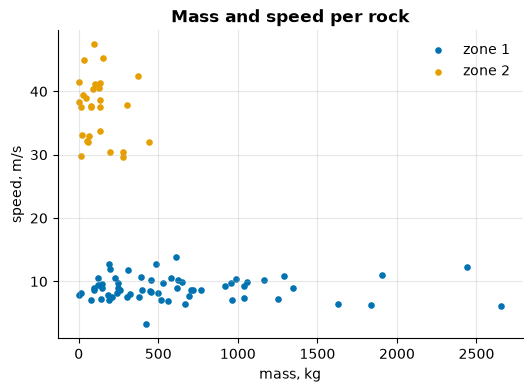

In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
for i, (zone, g) in enumerate(season.groupby("zone")):
    ax.scatter(g.mass, g.speed, s=14, label=zone, color=viz.PALETTE[i])
    r, p = stats.pearsonr(g.mass, g.speed)
    print(f"{zone}: correlation of mass and speed r = {r:+.2f} (p = {p:.2f}, n = {len(g)})")
ax.set(xlabel="mass, kg", ylabel="speed, m/s", title="Mass and speed per rock")
ax.legend();

No detectable dependence within either zone -- consistent with independence, which is how the data
was generated. (A test that does not reject is not a proof: with 28 rocks only a strong dependence
would show.) *Between* the zones the picture is different: knowing the zone tells you a great deal
about the speed. The zone is a variable to condition on.

In [3]:
joint = pd.crosstab(season.zone, pd.cut(season.speed, [0, 15, 30, 60], labels=["slow", "medium", "fast"]),
                    normalize=True).round(3)
print("joint P(zone, speed class):")
print(joint)
print("\nP(fast | zone 2) =", round(joint.loc["zone 2", "fast"] / joint.loc["zone 2"].sum(), 3))

joint P(zone, speed class):
speed    slow  medium   fast
zone                        
zone 1  0.685   0.000  0.000
zone 2  0.000   0.022  0.292

P(fast | zone 2) = 0.93


## Bayes' theorem

$$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}$$

A sensor on the net reports when it thinks a dangerous rock (over 500 kJ) arrived. It catches 99 %
of the dangerous rocks and wrongly fires on 2 % of the harmless ones. Dangerous rocks are rare. The
sensor fires -- how likely is the rock dangerous?

In [4]:
zones = rf.true_zones()
rates = np.array([z.rate_per_year() for z in zones])
shares = np.array([rf.p_energy_at_least(z.mass, z.speed, rf.WEAK_KJ) for z in zones])
p_danger = float((rates * shares).sum() / rates.sum())     # the share of all rocks over 500 kJ
print(f"P(a rock is dangerous) = {p_danger:.4f} -- about 1 in {1 / p_danger:,.0f}")
sens, false_alarm = 0.99, 0.02
p_fire = sens * p_danger + false_alarm * (1 - p_danger)
posterior = sens * p_danger / p_fire
print(f"P(dangerous | sensor fires) = {posterior:.1%}")

# check by simulation
n = 1_000_000
dangerous = rng.random(n) < p_danger
fires = np.where(dangerous, rng.random(n) < sens, rng.random(n) < false_alarm)
print(f"simulated: {dangerous[fires].mean():.1%} of the alarms were dangerous rocks")

P(a rock is dangerous) = 0.0011 -- about 1 in 881
P(dangerous | sensor fires) = 5.3%
simulated: 5.3% of the alarms were dangerous rocks


A 99 %-sensitive sensor is right about one alarm in twenty: dangerous rocks are about 1 in 900,
and the false alarms on the other 899 outnumber them. That is the **base-rate fallacy**. It is why a positive screening test needs a
second test, and why an alarm is a reason to look, not a conclusion.

## What to remember

- Conditioning restricts the world to what you know; independence means knowing does not help.
- A non-significant correlation is weak evidence of independence when the sample is small.
- Bayes turns $P(B \mid A)$ into $P(A \mid B)$; the base rate dominates when $A$ is rare.

## Exercises

1. How good must the false-alarm rate be for half of the alarms to be real?
2. Two independent sensors both fire. What is $P(\text{dangerous})$ now?
3. Simulate mass and speed with a correlation of 0.5. How many rocks until the test detects it?

**Next:** [Chapter 5 · The law of large numbers and the CLT](05-law-of-large-numbers-and-clt.ipynb)